# 11. Pooling Enrolled: Why Weren't Some Predictors Associated?

**Round 3 feedback:** *why weren't some categorical predictors associated with the outcome, and does pooling Enrolled with Graduate change that?*

In the assumptions notebook (section 1), five predictors showed **no significant association** with the three-class outcome:

- *Nacionality* and *International* (the same information; see assumptions section 2.2)
- *Educational special needs*
- *Inflation rate*
- *Curricular units 1st sem (credited)*

One possible reason is that **Enrolled sits between Dropout and Graduate**. If a predictor separates Dropout from everyone else, the Enrolled students can dilute that, and a three-group test also uses more degrees of freedom than a two-group one. So we rerun every association test under five versions of the target:

| Target | Groups compared | What it asks |
|---|---|---|
| 3-class | Dropout / Enrolled / Graduate | The original test |
| **Dropout vs. not** | Dropout vs. (Enrolled + Graduate) | Does the predictor flag dropouts? (the early-warning question, and the professor's pooling) |
| Graduate vs. not | Graduate vs. (Dropout + Enrolled) | Does it flag on-time graduates? |
| Enrolled vs. Graduate | Dropouts removed | Does it separate the two "still in school" groups? |
| Dropout vs. Graduate | Enrolled removed | The two clear outcomes only |

Same methods as the assumptions notebook: chi-square + Cramér's V for categorical and binary predictors (with rare levels pooled into "Other"), Kruskal-Wallis + ε² for numeric ones. With 5 targets × 36 predictors = 180 tests, p-values are adjusted with the **Benjamini-Hochberg** false-discovery-rate correction.

## 11.0 Setup

In [1]:
import sys
from pathlib import Path

cwd = Path.cwd()
ROOT = next((p for p in (cwd, *cwd.parents) if (p / "src" / "preprocessing.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the project root or its notebooks/ directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_confint

from src.plotting import OUTCOME_ORDER, OUTCOME_PALETTE
from src.preprocessing import (
    BINARY_COLS,
    CATEGORICAL_COLS,
    NUMERIC_COLS,
    TARGET_COL,
    get_feature_availability_sets,
    load_data,
)

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
ALPHA = 0.05
FIG_DIR = ROOT / "reports" / "figures"
OUT_DIR = ROOT / "data" / "processed"
FIG_DIR.mkdir(parents=True, exist_ok=True)

df = load_data()
y = df[TARGET_COL]
print(df.shape)

(4424, 37)


## 11.1 Run every association test under every target

In [3]:
TARGETS = {
    "3-class": y,
    "Dropout vs. not": y.where(y == "Dropout", "Not dropout"),
    "Graduate vs. not": y.where(y == "Graduate", "Not graduate"),
    "Enrolled vs. Graduate": y.where(y != "Dropout"),
    "Dropout vs. Graduate": y.where(y != "Enrolled"),
}


def collapse_rare_levels(s, target, min_count=50, min_cell=5):
    """Same rule as the assumptions notebook: pool levels that are small overall or in any outcome."""
    ct = pd.crosstab(s, target)
    rare = ct.index[(ct.sum(axis=1) < min_count) | (ct.min(axis=1) < min_cell)]
    return s.where(~s.isin(rare), "Other").astype(str)


def cramers_v(ct):
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))


rows = []
for target_name, target in TARGETS.items():
    keep = target.notna()
    t = target[keep]
    for col in CATEGORICAL_COLS + BINARY_COLS:
        s = df.loc[keep, col]
        if col in CATEGORICAL_COLS:
            s = collapse_rare_levels(s, t)
        ct = pd.crosstab(s, t)
        chi2, p, dof, _ = stats.chi2_contingency(ct, correction=False)
        rows.append({"Target": target_name, "Predictor": col, "Type": "Categorical",
                     "Effect size": cramers_v(ct), "Effect measure": "Cramér's V", "p-value": p})
    for col in NUMERIC_COLS:
        groups = [df.loc[keep & (target == g), col] for g in t.unique()]
        H, p = stats.kruskal(*groups)
        n, k = keep.sum(), len(groups)
        rows.append({"Target": target_name, "Predictor": col, "Type": "Numeric",
                     "Effect size": max((H - k + 1) / (n - k), 0), "Effect measure": "ε²", "p-value": p})

assoc = pd.DataFrame(rows)
assoc["p (BH-adjusted)"] = multipletests(assoc["p-value"], method="fdr_bh")[1]
assoc["Significant"] = assoc["p (BH-adjusted)"] < ALPHA
assoc.to_csv(OUT_DIR / "feedback_associations_by_target.csv", index=False)

sig_counts = assoc.groupby("Target")["Significant"].sum().reindex(TARGETS)
print("Number of predictors (out of 36) significantly associated, after BH correction:")
display(sig_counts.to_frame("Significant predictors"))

Number of predictors (out of 36) significantly associated, after BH correction:


,Significant predictors
Target,
3-class,31
Dropout vs. not,29
Graduate vs. not,31
Enrolled vs. Graduate,27
Dropout vs. Graduate,29


## 11.2 Do the five "not associated" predictors become associated after pooling?

In [4]:
NULL_PREDICTORS = ["Nacionality", "International", "Educational special needs",
                   "Inflation rate", "Curricular units 1st sem (credited)"]

null_table = (assoc[assoc["Predictor"].isin(NULL_PREDICTORS)]
              .pivot(index="Predictor", columns="Target", values="p (BH-adjusted)")
              .reindex(index=NULL_PREDICTORS, columns=list(TARGETS)))
print("BH-adjusted p-values (significant if < 0.05):")
display(null_table.map(lambda v: f"{v:.2f}"))

effect_table = (assoc[assoc["Predictor"].isin(NULL_PREDICTORS)]
                .pivot(index="Predictor", columns="Target", values="Effect size")
                .reindex(index=NULL_PREDICTORS, columns=list(TARGETS)))
print("Effect sizes (Cramér's V for categorical, ε² for numeric):")
display(effect_table.round(3))

BH-adjusted p-values (significant if < 0.05):


Target,3-class,Dropout vs. not,Graduate vs. not,Enrolled vs. Graduate,Dropout vs. Graduate
Predictor,,,,,
Nacionality,0.56,0.54,0.86,0.43,0.73
International,0.56,0.54,0.86,0.43,0.73
Educational special needs,0.75,0.86,0.54,0.48,0.69
Inflation rate,0.34,0.15,0.25,0.79,0.15
Curricular units 1st sem (credited),0.34,0.48,0.16,0.22,0.28


Effect sizes (Cramér's V for categorical, ε² for numeric):


Target,3-class,Dropout vs. not,Graduate vs. not,Enrolled vs. Graduate,Dropout vs. Graduate
Predictor,,,,,
Nacionality,0.017,0.010,0.003,0.016,0.006
International,0.017,0.010,0.003,0.016,0.006
Educational special needs,0.012,0.003,0.010,0.014,0.007
Inflation rate,0.000,0.000,0.000,0.000,0.000
Curricular units 1st sem (credited),0.000,0.000,0.000,0.000,0.000


**Reading this:** pooling doesn't rescue any of them. Pooling also doesn't raise the overall count of significant predictors (31 of 36 for the 3-class target vs. 29 for Dropout vs. not). All five stay non-significant under **every** version of the target, and their effect sizes stay near zero (V ≈ 0.01, ε² < 0.001). So the Enrolled class wasn't hiding a real association. Section 11.3 looks at why each is null.

## 11.3 Why each one is null

There are two different kinds of "not associated":

- **No real difference:** the groups have nearly identical outcomes.
- **Too few students to tell:** a difference might exist, but the group is too small to detect it.

For the small binary groups, we show each group's dropout rate with a 95% confidence interval, the 95% confidence interval for the difference, and the **smallest difference we had 80% power to detect** at α = 0.05. If that smallest detectable difference is large, the honest conclusion is "we couldn't detect it," not "there's no effect."

In [5]:
def small_group_check(flag, label):
    """Dropout rate in a small binary group vs. everyone else, with power."""
    is_drop = (y == "Dropout")
    n1, n0 = int(flag.sum()), int((~flag).sum())
    x1, x0 = int(is_drop[flag].sum()), int(is_drop[~flag].sum())
    p1, p0 = x1 / n1, x0 / n0
    lo1, hi1 = proportion_confint(x1, n1, method="wilson")
    se = np.sqrt(p1 * (1 - p1) / n1 + p0 * (1 - p0) / n0)
    # smallest detectable effect (Cohen's h) at 80% power, converted back to percentage points
    h = NormalIndPower().solve_power(nobs1=n1, ratio=n0 / n1, alpha=ALPHA, power=0.8)
    p_detect = np.sin(np.arcsin(np.sqrt(p0)) + h / 2) ** 2
    return {"Group": label, "n in group": n1,
            "Dropout rate (group)": p1, "95% CI (group)": f"{lo1:.1%} to {hi1:.1%}",
            "Dropout rate (everyone else)": p0,
            "Difference": p1 - p0,
            "95% CI of difference": f"{p1 - p0 - 1.96 * se:+.1%} to {p1 - p0 + 1.96 * se:+.1%}",
            "Smallest detectable difference (80% power)": p_detect - p0}


small_groups = pd.DataFrame([
    small_group_check(df["International"] == 1, "International (= non-Portuguese)"),
    small_group_check(df["Educational special needs"] == 1, "Educational special needs"),
    small_group_check(df["Curricular units 1st sem (credited)"] > 0, "Any Sem 1 credited units"),
])
display(small_groups.style.format({
    "Dropout rate (group)": "{:.1%}", "Dropout rate (everyone else)": "{:.1%}",
    "Difference": "{:+.1%}", "Smallest detectable difference (80% power)": "{:+.1%}"}))

print("Outcome mix of each small group:")
for label, flag in [("International", df["International"] == 1),
                    ("Special needs", df["Educational special needs"] == 1),
                    ("Any Sem 1 credited", df["Curricular units 1st sem (credited)"] > 0),
                    ("Everyone", pd.Series(True, index=df.index))]:
    mix = y[flag].value_counts(normalize=True).reindex(OUTCOME_ORDER)
    print(f"  {label:20s} n={int(flag.sum()):5d}  " + "  ".join(f"{k} {v:.1%}" for k, v in mix.items()))
print()
print("Median age at enrollment: credited =",
      df.loc[df["Curricular units 1st sem (credited)"] > 0, "Age at enrollment"].median(),
      "| not credited =", df.loc[df["Curricular units 1st sem (credited)"] == 0, "Age at enrollment"].median())

,Group,n in group,Dropout rate (group),95% CI (group),Dropout rate (everyone else),Difference,95% CI of difference,Smallest detectable difference (80% power)
0,International (= non-Portuguese),110,29.1%,21.4% to 38.2%,32.2%,-3.1%,-11.7% to +5.5%,+13.1%
1,Educational special needs,51,33.3%,22.0% to 47.0%,32.1%,+1.2%,-11.8% to +14.2%,+19.3%
2,Any Sem 1 credited units,577,31.0%,27.4% to 34.9%,32.3%,-1.3%,-5.3% to +2.8%,+6.0%


Outcome mix of each small group:
  International        n=  110  Dropout 29.1%  Enrolled 21.8%  Graduate 49.1%
  Special needs        n=   51  Dropout 33.3%  Enrolled 21.6%  Graduate 45.1%
  Any Sem 1 credited   n=  577  Dropout 31.0%  Enrolled 16.8%  Graduate 52.2%
  Everyone             n= 4424  Dropout 32.1%  Enrolled 17.9%  Graduate 49.9%

Median age at enrollment: credited = 24.0 | not credited = 20.0


**The macroeconomic variables are a special case.** *Inflation rate*, *Unemployment rate*, and *GDP* aren't measured per student. Each student gets the value for the year they enrolled, so the three columns together identify only **10 enrollment cohorts**. Testing them student by student treats 4,424 rows as independent when there are really 10 values, and treating inflation as a number assumes dropout rises or falls steadily with it. Below, the cohort is treated as one categorical variable instead.

In [6]:
cohort = (df["Inflation rate"].astype(str) + " / " + df["Unemployment rate"].astype(str)
          + " / " + df["GDP"].astype(str))
print("Distinct values: inflation", df["Inflation rate"].nunique(),
      "| unemployment", df["Unemployment rate"].nunique(),
      "| GDP", df["GDP"].nunique(), "| cohorts (all three together)", cohort.nunique())

cohort_rows = []
for target_name, target in TARGETS.items():
    keep = target.notna()
    ct = pd.crosstab(cohort[keep], target[keep])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    cohort_rows.append({"Target": target_name, "Chi2": chi2, "df": dof, "p-value": p,
                        "Cramér's V": cramers_v(ct)})
display(pd.DataFrame(cohort_rows).round(4))

cohort_mix = pd.crosstab(cohort, y, normalize="index")[OUTCOME_ORDER]
cohort_mix["n"] = cohort.value_counts()
cohort_mix.index.name = "Cohort (inflation / unemployment / GDP)"
display(cohort_mix.sort_values("Dropout").round(3))

Distinct values: inflation 9 | unemployment 10 | GDP 10 | cohorts (all three together) 10


,Target,Chi2,df,p-value,Cramér's V
0,3-class,51.9650,18,0.0000,0.0766
1,Dropout vs. not,32.9533,9,0.0001,0.0863
2,Graduate vs. not,25.8871,9,0.0021,0.0765
3,Enrolled vs. Graduate,19.5260,9,0.0211,0.0806
4,Dropout vs. Graduate,31.9886,9,0.0002,0.0939


Target,Dropout,Enrolled,Graduate,n
Cohort (inflation / unemployment / GDP),,,,
0.5 / 12.4 / 1.79,0.240,0.202,0.557,445
1.4 / 8.9 / 3.51,0.277,0.209,0.514,368
0.6 / 11.1 / 2.02,0.283,0.162,0.556,414
-0.3 / 13.9 / 0.79,0.303,0.164,0.533,390
-0.8 / 9.4 / -3.12,0.326,0.205,0.469,533
3.7 / 12.7 / -1.7,0.337,0.150,0.513,419
1.4 / 10.8 / 1.74,0.347,0.171,0.482,525
2.8 / 15.5 / -4.06,0.350,0.174,0.476,397
2.6 / 7.6 / 0.32,0.354,0.208,0.438,571


**Reading 11.3:**

- **International / Nacionality:** the dropout rate is 29.1% for international students vs. 32.2% for Portuguese students, a difference of about 3 points. With only 110 international students, the confidence interval for that difference is wide, and we only had 80% power to detect a difference of about 13 points (the 95% CI for the difference runs from about −12 to +6 points). So the right conclusion is that **any effect is too small for this sample to detect**, not that nationality doesn't matter.
- **Educational special needs:** only 51 students. The dropout rate (33.3%) is almost the same as everyone else's (32.1%), and the smallest detectable difference is about 19 points. **This test had almost no power.**
- **Credited units:** 13% of students (577) have any Semester 1 credited units, so this group is not small, and their outcome mix (31.0% Dropout, 16.8% Enrolled, 52.2% Graduate) is close to the overall mix. Credited units are units recognized from earlier study; these students are older (median age 24 vs. 20). The 95% CI for the dropout difference (about −5 to +3 points) rules out anything large, so here **there really is no meaningful difference.**
- **Inflation rate:** as a single number per student it shows nothing, but the **enrollment cohort does matter** (chi-square p < 0.001 for the 3-class target). Dropout ranges from 24.0% to 38.4% across cohorts, and the pattern doesn't line up with inflation in a straight line. Inflation is a poor stand-in for "which year did this student start," and with only 10 cohorts we can't separate economic conditions from anything else that changed between years.

**For the presentation:** "Pooling Enrolled with Graduate didn't change these results. Two of them (international, special needs) are groups too small to test: we couldn't detect a difference smaller than about 13–19 points. Credited units really don't matter, and the macroeconomic variables are actually 10 enrollment cohorts, which do differ, just not in step with inflation."

## 11.4 What pooling *does* show: which outcome each predictor separates

Comparing the **Dropout vs. not** test with the **Enrolled vs. Graduate** test shows something the three-class test hides: whether a predictor tells dropouts apart from everyone else, or tells the two "still in school" groups apart from each other.

In [7]:
wide = assoc.pivot(index="Predictor", columns="Target", values="Effect size")
wide_sig = assoc.pivot(index="Predictor", columns="Target", values="Significant")
day1_cols = get_feature_availability_sets(df)["Day 1"]

compare = pd.DataFrame({
    "Dropout vs. not": wide["Dropout vs. not"],
    "Enrolled vs. Graduate": wide["Enrolled vs. Graduate"],
    "Sig. (D vs. not)": wide_sig["Dropout vs. not"],
    "Sig. (E vs. G)": wide_sig["Enrolled vs. Graduate"],
    "Measure": assoc.drop_duplicates("Predictor").set_index("Predictor")["Effect measure"],
    "Day 1 predictor": [p in day1_cols for p in wide.index],
})
compare["Ratio (D vs. not ÷ E vs. G)"] = compare["Dropout vs. not"] / compare["Enrolled vs. Graduate"].clip(lower=1e-3)

day1_cat = compare[compare["Day 1 predictor"] & (compare["Measure"] == "Cramér's V")]
print("Day 1 categorical/binary predictors, sorted by how strongly they flag dropouts:")
display(day1_cat.sort_values("Dropout vs. not", ascending=False)
        [["Dropout vs. not", "Enrolled vs. Graduate", "Sig. (D vs. not)", "Sig. (E vs. G)"]].round(3))

d1 = compare[compare["Day 1 predictor"]]
print(f"Day 1 predictors significant for Dropout vs. not:       {int(d1['Sig. (D vs. not)'].sum())} of {len(d1)}")
print(f"Day 1 predictors significant for Enrolled vs. Graduate: {int(d1['Sig. (E vs. G)'].sum())} of {len(d1)}")
print(f"Median Cramér's V, Day 1 categorical: Dropout vs. not = {day1_cat['Dropout vs. not'].median():.3f}, "
      f"Enrolled vs. Graduate = {day1_cat['Enrolled vs. Graduate'].median():.3f}")

Day 1 categorical/binary predictors, sorted by how strongly they flag dropouts:


,Dropout vs. not,Enrolled vs. Graduate,Sig. (D vs. not),Sig. (E vs. G)
Predictor,,,,
Tuition fees up to date,0.429,0.115,True,True
Application mode,0.296,0.138,True,True
Course,0.260,0.315,True,True
Scholarship holder,0.245,0.202,True,True
Debtor,0.229,0.122,True,True
Gender,0.204,0.135,True,True
Mother's occupation,0.189,0.079,True,True
Previous qualification,0.189,0.069,True,True
Mother's qualification,0.187,0.080,True,True


Day 1 predictors significant for Dropout vs. not:       19 of 24
Day 1 predictors significant for Enrolled vs. Graduate: 16 of 24
Median Cramér's V, Day 1 categorical: Dropout vs. not = 0.187, Enrolled vs. Graduate = 0.079


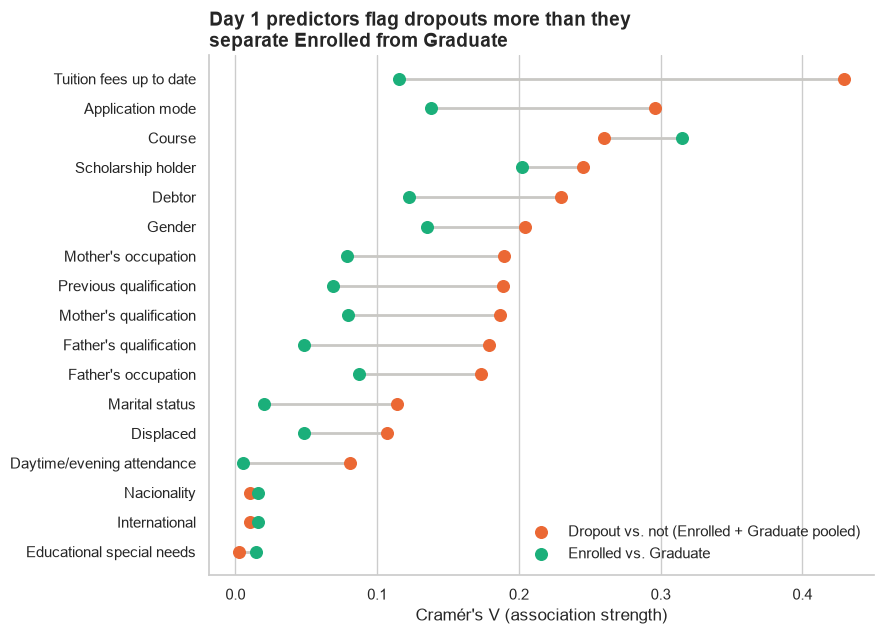

In [8]:
plot_df = day1_cat.sort_values("Dropout vs. not")
fig, ax = plt.subplots(figsize=(9, 6.5))
ypos = np.arange(len(plot_df))
ax.hlines(ypos, plot_df["Enrolled vs. Graduate"], plot_df["Dropout vs. not"], color="#c9c8c4", lw=2, zorder=1)
ax.scatter(plot_df["Dropout vs. not"], ypos, color=OUTCOME_PALETTE["Dropout"], s=70, zorder=2,
           label="Dropout vs. not (Enrolled + Graduate pooled)")
ax.scatter(plot_df["Enrolled vs. Graduate"], ypos, color=OUTCOME_PALETTE["Enrolled"], s=70, zorder=2,
           label="Enrolled vs. Graduate")
ax.set_yticks(ypos, plot_df.index)
ax.set_xlabel("Cramér's V (association strength)")
ax.set_title("Day 1 predictors flag dropouts more than they\nseparate Enrolled from Graduate", loc="left", fontsize=14, fontweight="bold")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
sns.despine()
plt.tight_layout()
plt.savefig(FIG_DIR / "feedback_pooling_dropout_vs_enrolled_graduate.png", dpi=200, bbox_inches="tight")
plt.show()

**Reading 11.4:** pooling shows *which* outcome each predictor separates. Most Day 1 predictors are about **twice as strong at flagging dropouts** as at separating Enrolled from Graduate (median Cramér's V 0.19 vs. 0.08):

- *Tuition fees up to date* (0.43 vs. 0.12), the parental variables (≈0.18 vs. 0.05–0.09), and *Previous qualification* (0.19 vs. 0.07) flag dropouts much more than they split Enrolled from Graduate.
- *Daytime/evening attendance*, *Marital status*, and *Father's qualification* are significant for Dropout vs. not but **not** for Enrolled vs. Graduate at all.
- The exception is **Course** (0.26 vs. 0.32): some programs have many more students still enrolled past the normal length. *Scholarship holder* is also similar for both (0.25 vs. 0.20).

Many predictors still differ significantly between Enrolled and Graduate (16 of 24 Day 1 predictors), so they aren't identical groups. But at enrollment, Enrolled students are **much closer to graduates than to dropouts**. This supports three things:

- **Pooling Enrolled with Graduate makes sense for early warning** (notebook 10's "flag Dropout or not" rule): the Day 1 information mostly separates dropouts from everyone else.
- It helps explain why the three-class models struggle with Enrolled (notebook 09): apart from course, the Day 1 differences between Enrolled and Graduate are small.
- It's consistent with the dataset's definition: outcomes were recorded at the end of the normal course length, so "Enrolled" means *not finished on time*, not *failed*. **(Check the exact wording in Martins et al. before presenting this.)**

## 11.5 Summary for the final presentation

| Question | What we tested | Finding |
|---|---|---|
| Why weren't some predictors associated? Does pooling Enrolled + Graduate help? | All 36 predictors under 5 target definitions, BH-corrected; power and confidence intervals for small groups; macro variables as cohorts | Pooling doesn't rescue them. International and special needs are **too small to test** (we'd only detect differences of about 13–19 points); credited units **truly don't matter**; macro variables are **10 cohorts**, which do differ, just not in step with inflation |
| What does pooling show instead? | Dropout vs. not compared with Enrolled vs. Graduate | Day 1 predictors are about **twice as strong** at flagging dropouts as at separating Enrolled from Graduate (median V 0.19 vs. 0.08), so **at enrollment, Enrolled students are much closer to graduates than to dropouts** (course is the exception). This supports a Dropout-vs-not early-warning model |

Outputs: `data/processed/feedback_associations_by_target.csv`, `reports/figures/feedback_pooling_dropout_vs_enrolled_graduate.png`